In [28]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append('..')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import fastf1
from src.params import CAR_2022, G

fastf1.Cache.enable_cache('../cache')
race = fastf1.get_session(2022, 'Spain', 'R')
race.load(laps=True, telemetry=False, weather=True, messages=True)
print(race.event['EventName'], '|', race.name, '|', race.date)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


c:\Users\Ryan\Documents\f1-lapsim\.venv\Lib\site-packages\fastf1\req.py:251: FutureWarning: `.enable_cache` is deprecated and will be removed in a future version. Use `.configure` instead.
  warnings.warn("`.enable_cache` is deprecated and will be removed in a "
core           INFO 	Loading data for Spanish Grand Prix - Race [v3.9.0]
req            INFO 	Using cached data for session_info
req            INFO 	Using cached data for driver_info
req            INFO 	Using cached data for session_status_data
req            INFO 	Using cached data for lap_count
req            INFO 	Using cached data for track_status_data
req            INFO 	Using cached data for _extended_timing_data
req            INFO 	Using cached data for timing_app_data
core           INFO 	Processing timing data...
req            INFO 	Using cached data for weather_data
req            INFO 	Using cached data for race_control_messages
core           INFO 	Finished loading data for 20 drivers: ['1', '11', '63', '55', '

Spanish Grand Prix | Race | 2022-05-22 13:00:00


In [29]:
# =================================
# Seeing what a row looks like
# =================================

laps = race.laps
cols = ['Driver', 'LapNumber', 'LapTime', 'Stint', 'Compound', 'TyreLife',
        'FreshTyre', 'PitInTime', 'PitOutTime', 'TrackStatus', 'IsAccurate',
        'Deleted', 'Position', 'Time', 'LapStartTime']

print(laps.shape)
print('Drivers:', laps['Driver'].nunique(), sorted(laps['Driver'].unique()))
print('Max lap number:', laps['LapNumber'].max())
print(laps.groupby('Driver').size().sort_values().to_string())
laps[cols].head(8)

(1230, 31)
Drivers: 20 ['ALB', 'ALO', 'BOT', 'GAS', 'HAM', 'LAT', 'LEC', 'MAG', 'MSC', 'NOR', 'OCO', 'PER', 'RIC', 'RUS', 'SAI', 'STR', 'TSU', 'VER', 'VET', 'ZHO']
Max lap number: 66.0
Driver
LEC    27
ZHO    28
LAT    64
ALB    64
MAG    64
ALO    65
RIC    65
GAS    65
STR    65
VET    65
TSU    65
MSC    65
PER    66
BOT    66
HAM    66
NOR    66
SAI    66
RUS    66
OCO    66
VER    66


,Driver,LapNumber,LapTime,Stint,Compound,TyreLife,FreshTyre,PitInTime,PitOutTime,TrackStatus,IsAccurate,Deleted,Position,Time,LapStartTime
0,VER,1.0,0 days 00:01:29.739000,1.0,SOFT,4.0,False,NaT,NaT,12,False,False,2.0,0 days 01:03:42.883000,0 days 01:02:12.915000
1,VER,2.0,0 days 00:01:27.509000,1.0,SOFT,5.0,False,NaT,NaT,1,True,False,2.0,0 days 01:05:10.392000,0 days 01:03:42.883000
2,VER,3.0,0 days 00:01:27.574000,1.0,SOFT,6.0,False,NaT,NaT,1,True,False,2.0,0 days 01:06:37.966000,0 days 01:05:10.392000
3,VER,4.0,0 days 00:01:27.601000,1.0,SOFT,7.0,False,NaT,NaT,1,True,False,2.0,0 days 01:08:05.567000,0 days 01:06:37.966000
4,VER,5.0,0 days 00:01:27.937000,1.0,SOFT,8.0,False,NaT,NaT,1,True,False,2.0,0 days 01:09:33.504000,0 days 01:08:05.567000
5,VER,6.0,0 days 00:01:27.761000,1.0,SOFT,9.0,False,NaT,NaT,1,True,False,2.0,0 days 01:11:01.265000,0 days 01:09:33.504000
6,VER,7.0,0 days 00:01:28.070000,1.0,SOFT,10.0,False,NaT,NaT,12,True,False,2.0,0 days 01:12:29.335000,0 days 01:11:01.265000
7,VER,8.0,0 days 00:01:28.115000,1.0,SOFT,11.0,False,NaT,NaT,1,True,False,2.0,0 days 01:13:57.450000,0 days 01:12:29.335000


In [30]:
# =================================
# Stints and strategies
# =================================

stints = (laps.dropna(subset=['Stint'])
              .groupby(['Driver', 'Stint'])
              .agg(compound=('Compound', 'first'),
                   first_lap=('LapNumber', 'min'),
                   last_lap=('LapNumber', 'max'),
                   n_laps=('LapNumber', 'size'),
                   age_start=('TyreLife', 'min'),
                   fresh=('FreshTyre', 'first'))
              .reset_index())
stints['Stint'] = stints['Stint'].astype(int)
print(stints.to_string(index=False))

strategy = stints.groupby('Driver')['compound'].agg(
    lambda c: '-'.join(str(x)[0] for x in c))
print('\n', strategy.value_counts().to_string())
print('\n', laps['Compound'].value_counts(dropna=False).to_string())

Driver  Stint compound  first_lap  last_lap  n_laps  age_start  fresh
   ALB      1     SOFT        1.0      11.0      11        1.0   True
   ALB      2   MEDIUM       12.0      25.0      14        1.0   True
   ALB      3     SOFT       26.0      45.0      20        1.0   True
   ALB      4   MEDIUM       46.0      54.0       9        1.0   True
   ALB      5     SOFT       55.0      64.0      10        4.0  False
   ALO      1     SOFT        1.0      10.0      10        1.0   True
   ALO      2   MEDIUM       11.0      31.0      21        1.0   True
   ALO      3     SOFT       32.0      53.0      22        1.0   True
   ALO      4     SOFT       54.0      65.0      12        3.0  False
   BOT      1     SOFT        1.0      14.0      14        4.0  False
   BOT      2   MEDIUM       15.0      34.0      20        1.0   True
   BOT      3   MEDIUM       35.0      66.0      32        1.0   True
   GAS      1     SOFT        1.0      10.0      10        1.0   True
   GAS      2   MEDI

In [31]:
# =================================
# Track status (Safety Car)
# =================================

status_by_lap = (laps.groupby('LapNumber')['TrackStatus']
                     .agg(lambda s: ''.join(sorted(set(''.join(s.dropna().astype(str)))))))
not_green = status_by_lap[status_by_lap != '1']
print(f'{len(not_green)} of {len(status_by_lap)} lap numbers not fully green for at least one driver:')
print(not_green.to_string())

rcm = race.race_control_messages
sc = rcm[rcm['Message'].str.contains('SAFETY CAR', case=False, na=False)]
print(sc[[c for c in ['Time', 'Lap', 'Message'] if c in sc.columns]].to_string(index=False))

5 of 66 lap numbers not fully green for at least one driver:
LapNumber
1.0    12
6.0    12
7.0    12
8.0    12
9.0    12
Empty DataFrame
Columns: [Time, Lap, Message]
Index: []


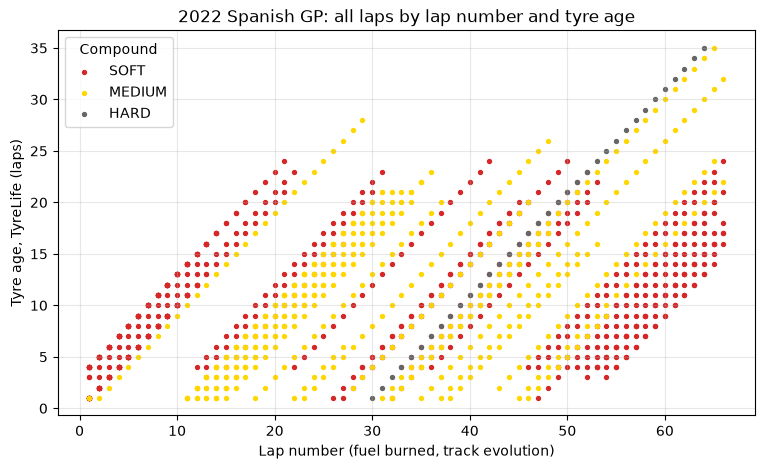

In [32]:
# =================================
# Figure
# =================================

colours = {'SOFT': 'tab:red', 'MEDIUM': 'gold', 'HARD': '0.4'}
fig, ax = plt.subplots(figsize=(9, 5))
for comp in ['SOFT', 'MEDIUM', 'HARD']:
    grp = laps[laps['Compound'] == comp]
    ax.scatter(grp['LapNumber'], grp['TyreLife'], s=8,
               color=colours.get(comp, 'tab:blue'), label=comp)
ax.set_xlabel('Lap number (fuel burned, track evolution)')
ax.set_ylabel('Tyre age, TyreLife (laps)')
ax.set_title('2022 Spanish GP: all laps by lap number and tyre age')
ax.legend(title='Compound')
ax.grid(alpha=0.3)
fig.savefig('../figures/06_coverage.png', dpi=150, bbox_inches='tight')
plt.show()

In [33]:
print(len(rcm), 'race control messages loaded')
print(stints[stints['compound'] == 'HARD'].to_string(index=False))
print(strategy.value_counts().to_string())

111 race control messages loaded
Driver  Stint compound  first_lap  last_lap  n_laps  age_start  fresh
   MAG      3     HARD       30.0      64.0      35        1.0   True
compound
S-M-S-S      6
S-M-M-S      3
S-S-M        2
S-M          2
S-S-M-S      2
S-M-S-M-S    1
S-M-H        1
M-S-M-S      1
S-M-M        1
S-M-S-M      1


In [34]:
df = laps.copy()
df['t'] = df['LapTime'].dt.total_seconds()

order = laps.sort_values('Time')
df['gap_ahead'] = order['Time'].diff().dt.total_seconds()
df['gap_behind'] = -order['Time'].diff(-1).dt.total_seconds()
print(df['gap_ahead'].describe())

count    1229.000000
mean        4.747733
std         4.650657
min         0.007000
25%         1.561000
50%         3.486000
75%         6.453000
max        40.485000
Name: gap_ahead, dtype: float64


In [35]:
# =================================
# Filters that don't look at lap time
# =================================

GAP_MIN = 1.5   # s; traffic threshold (DRS window is 1.0 s). A stated choice; test 1.0 and 2.0 later.

log = []
def keep(d, mask, rule):
    out = d[mask]
    log.append({'rule': rule, 'before': len(d), 'after': len(out)})
    print(f'{rule:32s} {len(d):5d} -> {len(out):5d}   dropped {len(d) - len(out):4d}')
    return out

c = df
c = keep(c, c['t'].notna(),                              'has a lap time')
c = keep(c, c['Compound'].notna() & c['Stint'].notna(),  'compound and stint known')
c = keep(c, c['LapNumber'] > 1,                          'not lap 1')
c = keep(c, c['PitInTime'].isna(),                       'not an in-lap')
c = keep(c, c['PitOutTime'].isna(),                      'not an out-lap')
c = keep(c, c['TrackStatus'] == '1',                     'green all lap')
c = keep(c, c['Deleted'] != True,                        'not deleted')
c = keep(c, c['IsAccurate'] == True,                     'FastF1 IsAccurate')
pre_traffic = c.copy()
c = keep(c, ~(c['gap_ahead'] < GAP_MIN),                 f'clear air (gap >= {GAP_MIN} s)')
clean_all = c.copy()

has a lap time                    1230 ->  1230   dropped    0
compound and stint known          1230 ->  1230   dropped    0
not lap 1                         1230 ->  1210   dropped   20
not an in-lap                     1210 ->  1157   dropped   53
not an out-lap                    1157 ->  1104   dropped   53
green all lap                     1104 ->  1060   dropped   44
not deleted                       1060 ->  1046   dropped   14
FastF1 IsAccurate                 1046 ->  1046   dropped    0
clear air (gap >= 1.5 s)          1046 ->   823   dropped  223


In [36]:
# =================================
# Outlier filter
# =================================

med = clean_all.groupby('Driver')['t'].transform('median')
clean = keep(clean_all, clean_all['t'] <= 1.07 * med, 'within 107 % of driver median')

within 107 % of driver median      823 ->   822   dropped    1


In [37]:
# =================================
# Whats left
# =================================

per_stint = (clean.groupby(['Driver', 'Stint'])
                  .agg(compound=('Compound', 'first'),
                       n_clean=('t', 'size'),
                       first_lap=('LapNumber', 'min'),
                       last_lap=('LapNumber', 'max'),
                       age_min=('TyreLife', 'min'),
                       age_max=('TyreLife', 'max'))
                  .reset_index())
print(clean['Compound'].value_counts().to_string())
print(per_stint.to_string(index=False))

Compound
SOFT      409
MEDIUM    387
HARD       26
Driver  Stint compound  n_clean  first_lap  last_lap  age_min  age_max
   ALB    1.0     SOFT        2        5.0       6.0      5.0      6.0
   ALB    2.0   MEDIUM       10       13.0      24.0      2.0     13.0
   ALB    3.0     SOFT       15       27.0      44.0      2.0     19.0
   ALB    4.0   MEDIUM        7       47.0      53.0      2.0      8.0
   ALB    5.0     SOFT        6       56.0      64.0      5.0     13.0
   ALO    2.0   MEDIUM       14       12.0      30.0      2.0     20.0
   ALO    3.0     SOFT       17       34.0      52.0      3.0     21.0
   ALO    4.0     SOFT       11       55.0      65.0      4.0     14.0
   BOT    1.0     SOFT        8        4.0      13.0      7.0     16.0
   BOT    2.0   MEDIUM       16       16.0      32.0      2.0     18.0
   BOT    3.0   MEDIUM       28       36.0      66.0      2.0     32.0
   GAS    2.0   MEDIUM       14       14.0      28.0      4.0     18.0
   GAS    3.0     SOFT    

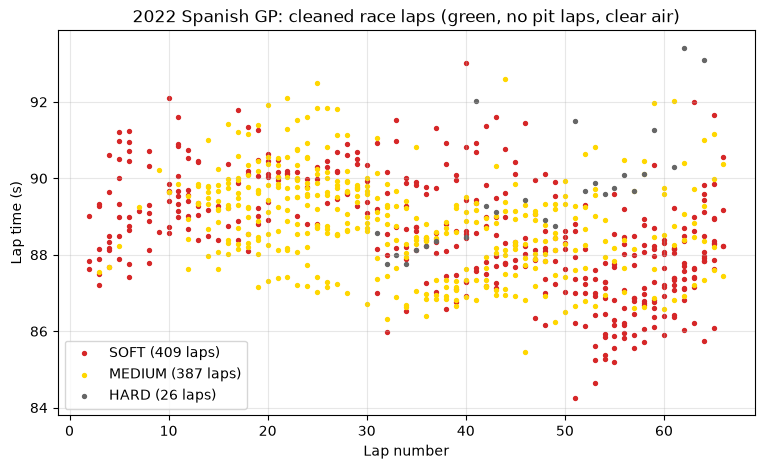

In [38]:
# =================================
# The cleaned laps
# =================================

fig, ax = plt.subplots(figsize=(9, 5))
for comp in ['SOFT', 'MEDIUM', 'HARD']:
    g = clean[clean['Compound'] == comp]
    ax.scatter(g['LapNumber'], g['t'], s=8, color=colours[comp],
               label=f'{comp} ({len(g)} laps)')
ax.set_xlabel('Lap number')
ax.set_ylabel('Lap time (s)')
ax.set_title('2022 Spanish GP: cleaned race laps (green, no pit laps, clear air)')
ax.legend()
ax.grid(alpha=0.3)
fig.savefig('../figures/06_clean_laps.png', dpi=150, bbox_inches='tight')
plt.show()

In [39]:
# =================================
# Choosing the held out stints by rule
# =================================

finish = race.results.set_index('Abbreviation')['Position']

final = per_stint.loc[per_stint.groupby('Driver')['Stint'].idxmax()].copy()
final['pos'] = final['Driver'].map(finish)
print(final.sort_values('pos').to_string(index=False))

mid = final[final['pos'].between(7, 12) & (final['n_clean'] >= 10)]
mid_pick = mid.sort_values('n_clean', ascending=False).iloc[0]['Driver']
held_out = [tuple(r) for r in final.loc[final['Driver'].isin(['VER', mid_pick]),
                                        ['Driver', 'Stint']].to_numpy()]
print('Held out:', held_out)

clean = clean.copy()
clean['held_out'] = [(d, s) in held_out for d, s in zip(clean['Driver'], clean['Stint'])]
print(clean['held_out'].sum(), 'held-out laps,', (~clean['held_out']).sum(), 'training laps')

Driver  Stint compound  n_clean  first_lap  last_lap  age_min  age_max  pos
   VER    4.0   MEDIUM       18       46.0      66.0      2.0     22.0  1.0
   PER    4.0     SOFT        8       57.0      65.0      7.0     15.0  2.0
   RUS    4.0     SOFT       14       53.0      66.0      4.0     17.0  3.0
   SAI    4.0     SOFT       14       47.0      66.0      5.0     24.0  4.0
   HAM    4.0     SOFT       11       51.0      65.0      6.0     20.0  5.0
   BOT    3.0   MEDIUM       28       36.0      66.0      2.0     32.0  6.0
   OCO    4.0     SOFT       13       54.0      66.0      5.0     17.0  7.0
   NOR    4.0     SOFT       13       53.0      66.0      5.0     18.0  8.0
   ALO    4.0     SOFT       11       55.0      65.0      4.0     14.0  9.0
   TSU    4.0     SOFT       11       54.0      65.0      5.0     16.0 10.0
   VET    3.0   MEDIUM       18       45.0      65.0      4.0     24.0 11.0
   RIC    4.0     SOFT       13       50.0      65.0      5.0     20.0 12.0
   GAS    4.

In [40]:
# =================================
# The design matrix
# =================================

def design(d, drivers):
    cols = {}
    for drv in drivers:
        cols[f'd_{drv}'] = (d['Driver'] == drv).astype(float)
    for comp in ['MEDIUM', 'HARD']:
        cols[f'b_{comp}'] = (d['Compound'] == comp).astype(float)
    cols['c_lap'] = d['LapNumber'].astype(float)
    for comp in ['SOFT', 'MEDIUM', 'HARD']:
        cols[f'k_{comp}'] = d['TyreLife'] * (d['Compound'] == comp)
    return pd.DataFrame(cols)

train = clean[~clean['held_out']]
drivers = sorted(train['Driver'].unique())
X = design(train, drivers)
y = train['t'].to_numpy()
print(X.shape)
X.head(3)

(786, 26)


,d_ALB,d_ALO,d_BOT,d_GAS,d_HAM,d_LAT,d_LEC,d_MAG,d_MSC,d_NOR,...,d_TSU,d_VER,d_VET,d_ZHO,b_MEDIUM,b_HARD,c_lap,k_SOFT,k_MEDIUM,k_HARD
5,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,6.0,9.0,0.0,0.0
7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,8.0,11.0,0.0,0.0
30,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,31.0,6.0,0.0,0.0


In [41]:
# =================================
# Solving and checking identifiability
# =================================

beta, rss, rank, sv = np.linalg.lstsq(X.to_numpy(), y, rcond=None)
print(f'rank {rank} of {X.shape[1]} columns;  condition number {sv[0] / sv[-1]:.0f}')

resid = y - X.to_numpy() @ beta
n, p = X.shape
sigma2 = resid @ resid / (n - p)
cov = sigma2 * np.linalg.inv(X.to_numpy().T @ X.to_numpy())
coef = pd.DataFrame({'value': beta, 'se': np.sqrt(np.diag(cov))}, index=X.columns)
print(f'residual RMS {np.sqrt(resid @ resid / n):.3f} s over {n} laps')
print(coef.loc[['c_lap', 'k_SOFT', 'k_MEDIUM', 'k_HARD', 'b_MEDIUM', 'b_HARD']].round(4).to_string())

rank 26 of 26 columns;  condition number 791
residual RMS 0.646 s over 786 laps
           value      se
c_lap    -0.0500  0.0016
k_SOFT    0.1456  0.0068
k_MEDIUM  0.1222  0.0055
k_HARD    0.1610  0.0128
b_MEDIUM  0.5652  0.1124
b_HARD    0.5993  0.3142


In [42]:
# =================================
# The fit as a function
# =================================

def is_held(d):
    return np.array([(a, b) in held_out for a, b in zip(d['Driver'], d['Stint'])])

def fit(d):
    drv = sorted(d['Driver'].unique())
    X = design(d, drv)
    A = X.to_numpy()
    y = d['t'].to_numpy()
    beta, _, rank, sv = np.linalg.lstsq(A, y, rcond=None)
    resid = y - A @ beta
    n, p = A.shape
    cov = (resid @ resid / (n - p)) * np.linalg.inv(A.T @ A)
    return {'coef': pd.DataFrame({'value': beta, 'se': np.sqrt(np.diag(cov))}, index=X.columns),
            'cov': pd.DataFrame(cov, index=X.columns, columns=X.columns),
            'resid': pd.Series(resid, index=d.index),
            'rms': np.sqrt(resid @ resid / n), 'rank': rank, 'drivers': drv}

PHYS = ['c_lap', 'k_SOFT', 'k_MEDIUM', 'k_HARD', 'b_MEDIUM', 'b_HARD']
base = fit(train)
print(base['coef'].loc[PHYS].round(4).to_string())

se = base['coef']['se']
corr = base['cov'] / np.outer(se, se)
print('\nCorrelation of c_lap with each k:')
print(corr.loc['c_lap', ['k_SOFT', 'k_MEDIUM', 'k_HARD']].round(2).to_string())

           value      se
c_lap    -0.0500  0.0016
k_SOFT    0.1456  0.0068
k_MEDIUM  0.1222  0.0055
k_HARD    0.1610  0.0128
b_MEDIUM  0.5652  0.1124
b_HARD    0.5993  0.3142

Correlation of c_lap with each k:
k_SOFT     -0.21
k_MEDIUM   -0.35
k_HARD     -0.13


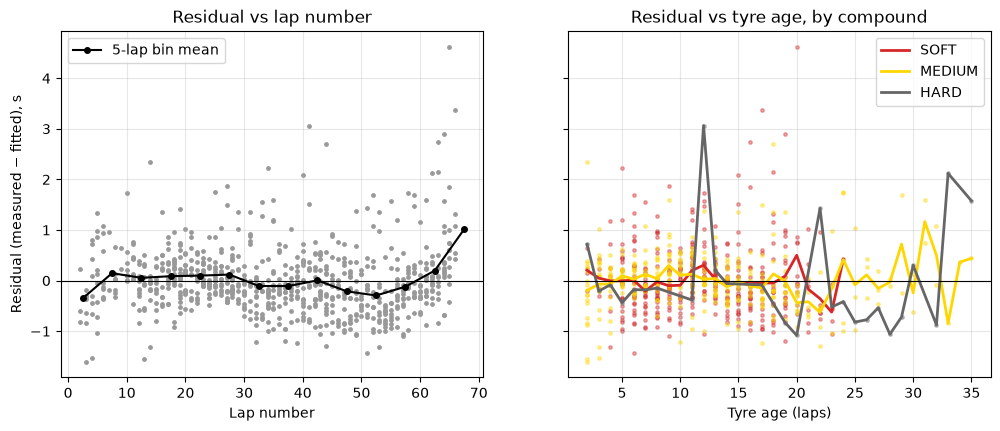

In [43]:
# =================================
# Figures
# =================================

r = base['resid']
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)

ax1.scatter(train['LapNumber'], r, s=6, color='0.6')
bins = (train['LapNumber'] // 5) * 5 + 2.5
mean_by_bin = r.groupby(bins).mean()
ax1.plot(mean_by_bin.index, mean_by_bin.values, 'k-o', ms=4, label='5-lap bin mean')
ax1.set_xlabel('Lap number'); ax1.set_ylabel('Residual (measured − fitted), s')
ax1.set_title('Residual vs lap number'); ax1.legend()

for comp in ['SOFT', 'MEDIUM', 'HARD']:
    m = train['Compound'] == comp
    ax2.scatter(train.loc[m, 'TyreLife'], r[m], s=6, color=colours[comp], alpha=0.4)
    by_age = r[m].groupby(train.loc[m, 'TyreLife']).mean()
    ax2.plot(by_age.index, by_age.values, '-', color=colours[comp], lw=2, label=comp)
ax2.set_xlabel('Tyre age (laps)'); ax2.set_title('Residual vs tyre age, by compound')
ax2.legend()

for ax in (ax1, ax2):
    ax.axhline(0, color='k', lw=0.8); ax.grid(alpha=0.3)
fig.savefig('../figures/06_residuals.png', dpi=150, bbox_inches='tight')
plt.show()

In [45]:
# =================================
# Sensitivity of the fit to the
# cleaning choices
# =================================

def outlier_rule(d):
    med = d.groupby('Driver')['t'].transform('median')
    return d[d['t'] <= 1.07 * med]

def train_of(d):
    return d[~is_held(d)]

variants = {
    'baseline (ahead >= 1.5 s)':      train,
    'no outlier rule':                train_of(pre_traffic[~(pre_traffic['gap_ahead'] < 1.5)]),
    'ahead >= 1.0 s':                 train_of(outlier_rule(pre_traffic[~(pre_traffic['gap_ahead'] < 1.0)])),
    'ahead >= 2.0 s':                 train_of(outlier_rule(pre_traffic[~(pre_traffic['gap_ahead'] < 2.0)])),
    '+ behind >= 1.5 s (blue flags)': train[~(train['gap_behind'] < 1.5)],
}

rows = {}
for name, d in variants.items():
    res = fit(d)
    row = res['coef']['value'].loc[PHYS].to_dict()
    row['n'] = len(d)
    row['rms'] = res['rms']
    row['rank'] = res['rank']
    rows[name] = row
sens = pd.DataFrame(rows).T
print(sens.round(3).to_string())

                                c_lap  k_SOFT  k_MEDIUM  k_HARD  b_MEDIUM  b_HARD      n    rms  rank
baseline (ahead >= 1.5 s)      -0.050   0.146     0.122   0.161     0.565   0.599  786.0  0.646  26.0
no outlier rule                -0.049   0.151     0.121   0.160     0.632   0.629  787.0  0.693  26.0
ahead >= 1.0 s                 -0.051   0.144     0.123   0.166     0.540   0.627  874.0  0.645  26.0
ahead >= 2.0 s                 -0.047   0.144     0.119   0.164     0.618   0.376  682.0  0.620  26.0
+ behind >= 1.5 s (blue flags) -0.052   0.150     0.131   0.156     0.537   0.872  638.0  0.621  26.0


In [46]:
# =================================
# Prediction and its errors
# =================================

held = clean[clean['held_out']].copy()
Xh = design(held, base['drivers'])
assert list(Xh.columns) == list(base['coef'].index)
held['pred'] = Xh.to_numpy() @ base['coef']['value'].to_numpy()

held['bench'] = held['Driver'].map(train.groupby('Driver')['t'].median())
held['err'] = held['t'] - held['pred']
held['err2'] = held['err'] ** 2
held['bench_err2'] = (held['t'] - held['bench']) ** 2

rms = lambda x: np.sqrt(x.mean())
summary = held.groupby('Driver').agg(n=('t', 'size'),
                                     bias=('err', 'mean'),
                                     rms=('err2', rms),
                                     rms_bench=('bench_err2', rms))
summary['slope_meas'] = [np.polyfit(g['LapNumber'], g['t'], 1)[0]
                         for _, g in held.groupby('Driver')]
summary['slope_pred'] = base['coef'].loc['c_lap', 'value'] + base['coef'].loc['k_MEDIUM', 'value']
print(summary.round(3).to_string())
print(held[['Driver', 'LapNumber', 'TyreLife', 't', 'pred', 'err']].round(2).to_string(index=False))

         n   bias    rms  rms_bench  slope_meas  slope_pred
Driver                                                     
VER     18  0.606  0.661      0.513       0.067       0.072
VET     18  0.040  0.700      1.300       0.003       0.072
Driver  LapNumber  TyreLife     t  pred   err
   VER       46.0       2.0 85.46 85.40  0.06
   VER       49.0       5.0 86.24 85.61  0.63
   VER       50.0       6.0 86.49 85.68  0.81
   VER       51.0       7.0 86.66 85.76  0.90
   VER       52.0       8.0 86.78 85.83  0.96
   VER       53.0       9.0 86.66 85.90  0.76
   VER       54.0      10.0 86.94 85.97  0.96
   VER       56.0      12.0 87.04 86.12  0.92
   VER       57.0      13.0 86.62 86.19  0.43
   VER       58.0      14.0 86.62 86.26  0.36
   VER       59.0      15.0 86.86 86.33  0.53
   VER       60.0      16.0 86.59 86.41  0.18
   VER       61.0      17.0 86.82 86.48  0.34
   VER       62.0      18.0 86.92 86.55  0.37
   VER       63.0      19.0 87.20 86.62  0.58
   VER       64.0      2

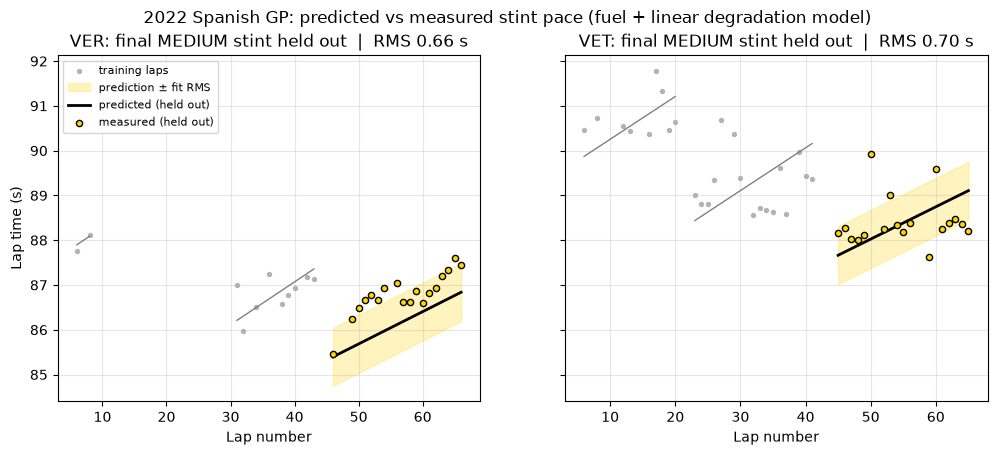

In [47]:
# =================================
# Figure
# =================================

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, drv in zip(axes, summary.index):
    tr = train[train['Driver'] == drv]
    fitted = tr['t'] - base['resid'][tr.index]
    ax.scatter(tr['LapNumber'], tr['t'], s=8, color='0.7', label='training laps')
    for _, g in tr.groupby('Stint'):
        ax.plot(g['LapNumber'], fitted[g.index], color='0.5', lw=1)

    h = held[held['Driver'] == drv]
    ax.fill_between(h['LapNumber'], h['pred'] - base['rms'], h['pred'] + base['rms'],
                    color='gold', alpha=0.25, label='prediction ± fit RMS')
    ax.plot(h['LapNumber'], h['pred'], 'k-', lw=2, label='predicted (held out)')
    ax.scatter(h['LapNumber'], h['t'], s=20, color='gold', edgecolor='k', zorder=3,
               label='measured (held out)')
    ax.set_title(f"{drv}: final MEDIUM stint held out  |  RMS {summary.loc[drv, 'rms']:.2f} s")
    ax.set_xlabel('Lap number'); ax.grid(alpha=0.3)
axes[0].set_ylabel('Lap time (s)')
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('2022 Spanish GP: predicted vs measured stint pace (fuel + linear degradation model)')
fig.savefig('../figures/06_stint_prediction.png', dpi=150, bbox_inches='tight')
plt.show()

In [48]:
# =================================
# Diagnostics
# =================================

print(per_stint[per_stint['Driver'] == 'VER'].to_string(index=False))

pos = laps[['Driver', 'LapNumber', 'Position', 'Time']].dropna()
p1 = pos[pos['Position'] == 1].set_index('LapNumber')
p2 = pos[pos['Position'] == 2].set_index('LapNumber')
lead = pd.DataFrame({'leader': p1['Driver'], 'second': p2['Driver'],
                     'gap_s': (p2['Time'] - p1['Time']).dt.total_seconds()})
print(lead.loc[44:66].round(1).to_string())

print(held.loc[held['Driver'] == 'VET',
               ['LapNumber', 't', 'err', 'gap_ahead', 'gap_behind']].round(2).to_string(index=False))

inside = (held['err'].abs() <= base['rms']).groupby(held['Driver']).mean()
print('\nFraction of held-out laps inside the ±RMS band:'); print(inside.round(2).to_string())

Driver  Stint compound  n_clean  first_lap  last_lap  age_min  age_max
   VER    1.0     SOFT        2        6.0       8.0      9.0     11.0
   VER    3.0     SOFT        9       31.0      43.0      6.0     18.0
   VER    4.0   MEDIUM       18       46.0      66.0      2.0     22.0
          leader second  gap_s
LapNumber                     
44.0         VER    PER   12.3
45.0         PER    VER    4.7
46.0         PER    VER    3.3
47.0         PER    VER    1.8
48.0         PER    VER    0.7
49.0         VER    PER    1.6
50.0         VER    PER    2.5
51.0         VER    PER    3.5
52.0         VER    PER    4.3
53.0         VER    PER    8.4
54.0         VER    PER   27.2
55.0         VER    PER   24.3
56.0         VER    PER   23.2
57.0         VER    PER   22.1
58.0         VER    PER   21.2
59.0         VER    PER   20.5
60.0         VER    PER   19.9
61.0         VER    PER   19.4
62.0         VER    PER   18.5
63.0         VER    PER   17.6
64.0         VER    PER   16.0
65.

In [49]:
# =================================
# Degredation with grip loss
# =================================

dt_dmu = -23.6    # s per unit mu_y: Stage 5 model sensitivity (LEC, sourced set, quali lap)
for comp in ['SOFT', 'MEDIUM', 'HARD']:
    k = base['coef'].loc[f'k_{comp}', 'value']
    dmu = k / abs(dt_dmu)
    print(f'{comp:7s} k = {k:.3f} s/lap  ->  mu_y loss {dmu:.4f} per lap '
          f'({100 * dmu / CAR_2022["mu_y"]:.2f} % of {CAR_2022["mu_y"]} per lap)')

SOFT    k = 0.146 s/lap  ->  mu_y loss 0.0062 per lap (0.39 % of 1.6 per lap)
MEDIUM  k = 0.122 s/lap  ->  mu_y loss 0.0052 per lap (0.32 % of 1.6 per lap)
HARD    k = 0.161 s/lap  ->  mu_y loss 0.0068 per lap (0.43 % of 1.6 per lap)


In [50]:
# =================================
# Checking that this model reproduces the notebook
# =================================

import src.degradation as deg

df_m = deg.add_gaps(laps)
clean_m, log_m = deg.clean_laps(df_m)
print(log_m.to_string(index=False))

base_m = deg.fit(clean_m[~deg.is_held(clean_m, held_out)])
print('same laps:  ', clean_m.index.equals(clean.index))
print('same coefs: ', np.allclose(base_m['coef']['value'], base['coef']['value']))
print(f"rank {base_m['rank']}, condition number {base_m['cond']:.0f}")

                          rule  before  after  dropped
                has a lap time    1230   1230        0
      compound and stint known    1230   1230        0
                     not lap 1    1230   1210       20
                 not an in-lap    1210   1157       53
                not an out-lap    1157   1104       53
                 green all lap    1104   1060       44
                   not deleted    1060   1046       14
             FastF1 IsAccurate    1046   1046        0
clear air (gap ahead >= 1.5 s)    1046    823      223
 within 107 % of driver median     823    822        1
same laps:   True
same coefs:  True
rank 26, condition number 791


In [51]:
   clean.groupby('Compound')['TyreLife'].max()

Compound
HARD      35.0
MEDIUM    35.0
SOFT      24.0
Name: TyreLife, dtype: float64